In [5]:
from pathlib import Path
import pandas as pd

data_path = Path("Anuran Calls (MFCCs)") / "Frogs_MFCCs.csv"
labels = ["Family", "Genus", "Species"]
dropped_cols = ["RecordID"]
test_size = 0.3

frogs = pd.read_csv(data_path).drop(columns=dropped_cols)
X, Y = frogs.drop(columns=labels), frogs[labels]
print(X.shape, Y.shape)

from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=test_size, random_state=42)
print(X_train.shape, X_test.shape)

(7195, 22) (7195, 3)
(5036, 22) (2159, 22)


**Question 1b**

In [6]:
import numpy as np

def exact_match(Y_true, Y_pred):
    return np.mean(np.all(np.asarray(Y_true) == np.asarray(Y_pred), axis=1))

def hamming_loss(Y_true, Y_pred):
    return np.mean(np.asarray(Y_true) != np.asarray(Y_pred))

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC

def make_rbf_svm(scale):
    return Pipeline([("scale", StandardScaler() if scale else "passthrough"),
                     ("clf", OneVsRestClassifier(SVC(kernel="rbf")))])

quick = True
cv_folds = 10
c_grid = np.logspace(-1, 4, 3 if QUICK else 6)
sigma_grid = np.linspace(0.1, 2, 3 if QUICK else 10)
param_grid = {"clf__estimator__C": C_GRID,
              "clf__estimator__gamma": 1 / (2 * SIGMA_GRID**2)}


In [8]:
for C in [c_grid.min(), c_grid.max()]:
    for sigma in [sigma_grid.min(), sigma_grid.max()]:
        model = make_rbf_svm(scale=False).set_params(clf__estimator__C=C,
                                                     clf__estimator__gamma=1 / (2 * sigma**2))
        train_acc = model.fit(X_train, Y_train["Species"]).score(X_train, Y_train["Species"])
        print(f"C={C:<8g} sigma={sigma:.2f}  train_acc={train_acc:.3f}")

C=0.1      sigma=0.10  train_acc=0.836
C=0.1      sigma=2.00  train_acc=0.870
C=10000    sigma=0.10  train_acc=1.000
C=10000    sigma=2.00  train_acc=1.000


In [9]:
from sklearn.model_selection import GridSearchCV

def fit_binary_relevance(make_model, param_grid, scale):
    Y_pred = pd.DataFrame(index=Y_test.index)
    for label in labels:
        search = GridSearchCV(make_model(scale), param_grid, cv=cv_folds, n_jobs=-1)
        search.fit(X_train, Y_train[label])
        Y_pred[label] = search.predict(X_test)
        print(f"{label:<8} best={search.best_params_}  cv_acc={search.best_score_:.3f}")
    return Y_pred

for scale in [False, True]:
    Y_pred_rbf = fit_binary_relevance(make_rbf_svm, param_grid, scale)
    print(f"scaled={scale}  exact_match={exact_match(Y_test, Y_pred_rbf):.3f}  "
          f"hamming_loss={hamming_loss(Y_test, Y_pred_rbf):.3f}\n")

Family   best={'clf__estimator__C': np.float64(10000.0), 'clf__estimator__gamma': np.float64(0.4535147392290249)}  cv_acc=0.989
Genus    best={'clf__estimator__C': np.float64(10000.0), 'clf__estimator__gamma': np.float64(0.4535147392290249)}  cv_acc=0.989
Species  best={'clf__estimator__C': np.float64(31.622776601683793), 'clf__estimator__gamma': np.float64(0.4535147392290249)}  cv_acc=0.989
scaled=False  exact_match=0.983  hamming_loss=0.009

Family   best={'clf__estimator__C': np.float64(31.622776601683793), 'clf__estimator__gamma': np.float64(0.125)}  cv_acc=0.990
Genus    best={'clf__estimator__C': np.float64(31.622776601683793), 'clf__estimator__gamma': np.float64(0.125)}  cv_acc=0.987
Species  best={'clf__estimator__C': np.float64(31.622776601683793), 'clf__estimator__gamma': np.float64(0.125)}  cv_acc=0.986
scaled=True  exact_match=0.983  hamming_loss=0.012



Gaussian SVM. 10-fold CV per label over C ∈ {0.1, 31.6, 10⁴} and σ ∈ {0.1, 1.05, 2} (γ = 1/2σ²).

**Question 1b.iii**

In [10]:
L1_C_GRID = np.logspace(-3, 3, 13)    
L1_PARAM_GRID = {"clf__C": L1_C_GRID}

In [11]:
from sklearn.svm import LinearSVC

def make_l1_svm(scale=True):
    return Pipeline([("scale", StandardScaler()),
                     ("clf", LinearSVC(penalty="l1", dual=False, max_iter=10000))])

In [12]:
Y_pred_l1 = fit_binary_relevance(make_l1_svm, L1_PARAM_GRID, scale=True)
print(f"exact_match={exact_match(Y_test, Y_pred_l1):.3f}  "
      f"hamming_loss={hamming_loss(Y_test, Y_pred_l1):.3f}")

Family   best={'clf__C': np.float64(1.0)}  cv_acc=0.941


/Users/dave/Documents/School/dsci552/DSCI552_Assignment_7/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/dave/Documents/School/dsci552/DSCI552_Assignment_7/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/dave/Documents/School/dsci552/DSCI552_Assignment_7/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/dave/Documents/School/dsci552/DSCI552_Assignment_7/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/dave/Documents/School/dsci552/DSCI552_Assignment_7/.venv/lib/python3.13/site-packages/sklearn/svm/_base.p

Genus    best={'clf__C': np.float64(10.0)}  cv_acc=0.953


/Users/dave/Documents/School/dsci552/DSCI552_Assignment_7/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/dave/Documents/School/dsci552/DSCI552_Assignment_7/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/dave/Documents/School/dsci552/DSCI552_Assignment_7/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/dave/Documents/School/dsci552/DSCI552_Assignment_7/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/dave/Documents/School/dsci552/DSCI552_Assignment_7/.venv/lib/python3.13/site-packages/sklearn/svm/_base.p

Species  best={'clf__C': np.float64(10.0)}  cv_acc=0.960
exact_match=0.913  hamming_loss=0.057


**Question 1b.iv**

In [13]:

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import balanced_accuracy_score

smote_c_grid = np.logspace(-2, 2, 9) 
smote_param_grid = {"clf__C": smote_c_grid}

def make_smote_l1_svm(scale=True):
    return ImbPipeline([("scale", StandardScaler()),
                        ("smote", SMOTE(random_state=42)),
                        ("clf", LinearSVC(penalty="l1", dual=False, max_iter=10000))])

In [14]:
Y_pred_smote = fit_binary_relevance(make_smote_l1_svm, smote_param_grid, scale=True)
print(f"exact_match={exact_match(Y_test, Y_pred_smote):.3f}  "
      f"hamming_loss={hamming_loss(Y_test, Y_pred_smote):.3f}")
for label in labels:
    print(f"{label:<8} L1={balanced_accuracy_score(Y_test[label], Y_pred_l1[label]):.3f}  "
          f"L1+SMOTE={balanced_accuracy_score(Y_test[label], Y_pred_smote[label]):.3f}")

Family   best={'clf__C': np.float64(1.0)}  cv_acc=0.921
Genus    best={'clf__C': np.float64(100.0)}  cv_acc=0.912
Species  best={'clf__C': np.float64(0.31622776601683794)}  cv_acc=0.957
exact_match=0.852  hamming_loss=0.077
Family   L1=0.690  L1+SMOTE=0.912
Genus    L1=0.769  L1+SMOTE=0.915
Species  L1=0.895  L1+SMOTE=0.928


**Question 2a**


best k: 2


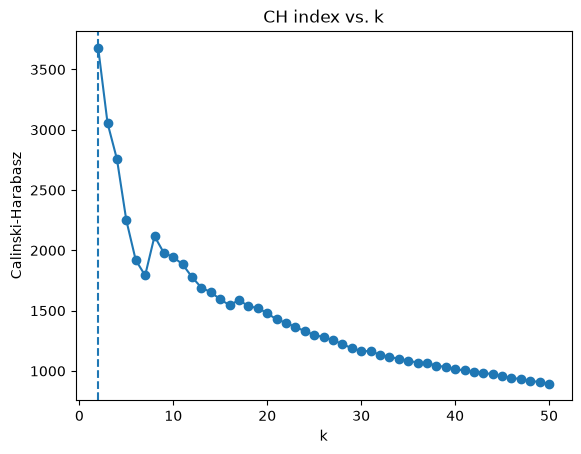

In [20]:
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
import matplotlib.pyplot as plt

K_RANGE = range(2, 51)
mc_runs = 50
X_all = frogs.drop(columns=labels) 
Y_all = frogs[labels]

def choose_k(X, seed):
    ch_scores = {k: calinski_harabasz_score(X, KMeans(n_clusters=k, random_state=seed).fit_predict(X))
                 for k in K_RANGE}
    return max(ch_scores, key=ch_scores.get), ch_scores


best_k, ch_scores = choose_k(X_all, 42)
print("best k:", best_k)
plt.plot(list(ch_scores), list(ch_scores.values()), marker="o")
plt.axvline(best_k, linestyle="--")
plt.xlabel("k"); plt.ylabel("Calinski-Harabasz"); plt.title("CH index vs. k")
plt.show()

**Question 2b**

In [18]:
cluster_ids = KMeans(n_clusters=best_k, random_state=42).fit_predict(X_all)
print(pd.Series(cluster_ids).value_counts())

cluster_majority = Y_all.groupby(cluster_ids).agg(lambda col: col.mode()[0])
print(cluster_majority)

0    3598
1    3597
Name: count, dtype: int64
            Family      Genus                 Species
0  Leptodactylidae  Adenomera  AdenomeraHylaedactylus
1          Hylidae  Hypsiboas       HypsiboasCordobae


With k = 2, k-means split the data into two nearly equal clusters, with majority triplets

**Question 2c**

In [21]:
def hamming_metrics(Y_true, Y_pred):
    wrong = np.asarray(Y_true) != np.asarray(Y_pred)   
    return {"hamming_distance": wrong.sum(axis=1).mean(),
            "hamming_loss": wrong.mean(),
            "hamming_score": 1 - wrong.mean()}

def monte_carlo_run(seed):
    k, _ = choose_k(X_all, seed)
    ids = KMeans(n_clusters=k, random_state=seed).fit_predict(X_all)
    majority = Y_all.groupby(ids).agg(lambda col: col.mode()[0])
    return {"seed": seed, "k": k, **hamming_metrics(Y_all, majority.loc[ids])}

Y_cluster = cluster_majority.loc[cluster_ids]
print(hamming_metrics(Y_all, Y_cluster))

mc_results = pd.DataFrame([monte_carlo_run(seed) for seed in range(mc_runs)])
print(mc_results["k"].value_counts())
print(mc_results[["hamming_distance", "hamming_loss", "hamming_score"]].agg(["mean", "std"]))

{'hamming_distance': np.float64(0.8956219596942321), 'hamming_loss': np.float64(0.2985406532314107), 'hamming_score': np.float64(0.7014593467685892)}
k
2    50
Name: count, dtype: int64
      hamming_distance  hamming_loss  hamming_score
mean      8.956220e-01  2.985407e-01   7.014593e-01
std       1.121495e-16  5.607473e-17   1.121495e-16


**ISLR 12.6.2**

a). Since the smallest distance is .3, (1,2) combine at .3.
- Then its d(1, 2, 3) = max(.4, .5) = .5, and d(1, 2, 4) = max(.7, .8) = .8 and d(3, 4) = .45 so (3, 4) combine at .45
- d(1, 2), (3, 4) = max(.4, .5, .7, .8) - .8 so everything combines at .8

```
0.80        +-----------+
            |           |
0.45        |         +---+
            |         |   |
0.30      +---+       |   |
          |   |       |   |
          1   2       3   4
```

b). 
- (1,2) combine at 0.3.
- Update: d((1,2),3) = min(0.4, 0.5) = 0.4 and d((1,2),4) = min(0.7, 0.8) = 0.7. The smallest is 0.4, so 3 joins (1,2) at 0.4.
- d((1,2,3),4) = min(0.7, 0.8, 0.45) = 0.45, so 4 joins at 0.45.

```
0.45           +----------+
               |          |
0.40        +-----+       |
            |     |       |
0.30      +---+   |       |
          |   |   |       |
          1   2   3       4
```



c). Cutting a into two clusters

Cut between 0.45 and 0.8, which gives (1, 2) and (3, 4).

d). Cutting b into two clusters

Cut between 0.4 and 0.45, which gives (1,2,3) and (4)

The two methods give different answers from the same data. Single linkage’s chaining pulls 3 in through its short link to 1 (0.4), even though 3 is far from 2 (0.5)

e).

```

0.80        +-----------+
            |           |
0.45        |         +---+
            |         |   |
0.30      +---+       |   |
          |   |       |   |
          2   1       4   3

```
